In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\taha2\Downloads\wdbc_with_header.csv")
df.head()

,id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842303,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,842304,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,842305,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,842306,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
df = df.drop(columns="id")
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})   # Malignant=1, Benign=0

print("Samples:", len(df), "| Features:", df.shape[1] - 1)
print(df["diagnosis"].value_counts())
df.isnull().sum()

Samples: 569 | Features: 30
diagnosis
0    357
1    212
Name: count, dtype: int64


diagnosis                  0
mean_radius                0
mean_texture               0
mean_perimeter             0
mean_area                  0
mean_smoothness            0
mean_compactness           0
mean_concavity             0
mean_concave_points        0
mean_symmetry              0
mean_fractal_dimension     0
radius_error               0
texture_error              0
perimeter_error            0
area_error                 0
smoothness_error           0
compactness_error          0
concavity_error            0
concave_points_error       0
symmetry_error             0
fractal_dimension_error    0
worst_radius               0
worst_texture              0
worst_perimeter            0
worst_area                 0
worst_smoothness           0
worst_compactness          0
worst_concavity            0
worst_concave_points       0
worst_symmetry             0
worst_fractal_dimension    0
dtype: int64

In [8]:
class Perceptron:
    def __init__(self, lr=0.01, epochs=100, seed=0):
        self.lr, self.epochs, self.seed = lr, epochs, seed

    @staticmethod
    def step(z):
        return np.where(z >= 0, 1, 0)

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        self.w = rng.normal(0, 0.01, X.shape[1])
        self.b = 0.0
        self.errors_per_epoch = []
        for _ in range(self.epochs):
            errors = 0
            for i in rng.permutation(len(X)):
                y_hat = self.step(X[i] @ self.w + self.b)
                update = self.lr * (y[i] - y_hat)
                self.w += update * X[i]
                self.b += update
                errors += int(update != 0)
            self.errors_per_epoch.append(errors)
        return self

    def predict(self, X):
        return self.step(X @ self.w + self.b)

In [9]:
X = df.drop(columns="diagnosis").values.astype(float)
y = df["diagnosis"].values.astype(int)

rng = np.random.default_rng(42)
idx = rng.permutation(len(X))
split = int(0.8 * len(X))
X_train, X_test = X[idx[:split]], X[idx[split:]]
y_train, y_test = y[idx[:split]], y[idx[split:]]

mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mu) / sigma
X_test = (X_test - mu) / sigma

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (455, 30)  Test: (114, 30)


In [10]:
model = Perceptron(lr=0.01, epochs=100).fit(X_train, y_train)
print("Weights:", np.round(model.w, 4))
print("Bias   :", round(model.b, 4))

Weights: [-0.1142  0.009  -0.0759  0.0141  0.066  -0.2882  0.3211  0.1179 -0.0514
  0.1116  0.1482 -0.0881  0.0088  0.2965  0.0494 -0.0357 -0.2032  0.1852
 -0.1599 -0.1694  0.1009  0.1806  0.1066  0.1937 -0.0885 -0.124   0.1799
  0.0962  0.2008  0.1468]
Bias   : 0.1


In [11]:
def evaluate(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return acc, prec, rec, f1, np.array([[tn, fp], [fn, tp]])

for name, Xs, ys in [("TRAIN", X_train, y_train), ("TEST", X_test, y_test)]:
    acc, prec, rec, f1, cm = evaluate(ys, model.predict(Xs))
    print(f"=== {name} RESULTS ===")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")
    print("Confusion matrix [[TN FP],[FN TP]]:\n", cm, "\n")

=== TRAIN RESULTS ===
Accuracy : 0.9824
Precision: 0.9709
Recall   : 0.9824
F1-score : 0.9766
Confusion matrix [[TN FP],[FN TP]]:
 [[280   5]
 [  3 167]] 

=== TEST RESULTS ===
Accuracy : 0.9737
Precision: 1.0000
Recall   : 0.9286
F1-score : 0.9630
Confusion matrix [[TN FP],[FN TP]]:
 [[72  0]
 [ 3 39]] 



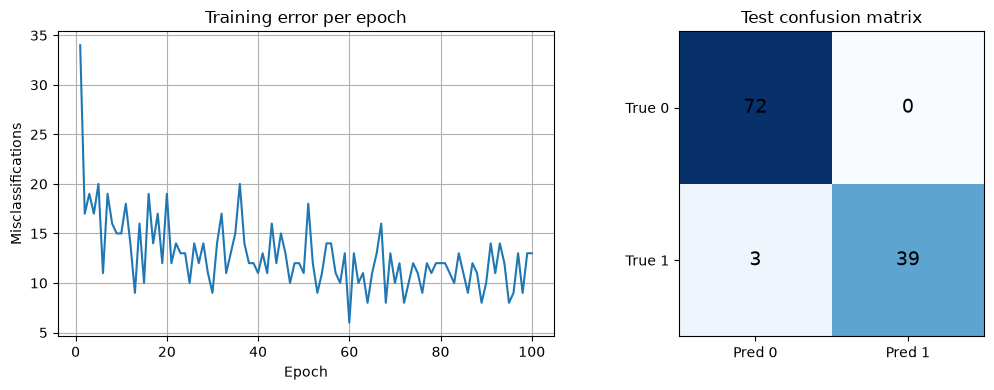

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(range(1, model.epochs + 1), model.errors_per_epoch)
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Misclassifications")
ax[0].set_title("Training error per epoch"); ax[0].grid(True)

_, _, _, _, cm = evaluate(y_test, model.predict(X_test))
ax[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
ax[1].set_xticks([0, 1]); ax[1].set_yticks([0, 1])
ax[1].set_xticklabels(["Pred 0", "Pred 1"]); ax[1].set_yticklabels(["True 0", "True 1"])
ax[1].set_title("Test confusion matrix")

plt.tight_layout()
plt.show()